# Milestone Three: Exploratory Data Analysis

## Project: Predictors of Diabetes Risk

### 1. Project Description

## 1. Project Description

The goal of this project is to explore factors that may be related to diabetes risk. I will use the Diabetes Health Indicators dataset, which includes information on BMI, blood pressure, cholesterol, physical activity, age, education, income, and other health-related factors.

I will use exploratory data analysis to look for patterns, check the quality of the data, and see which variables appear to be most related to diabetes status. This project could be useful for understanding which factors may be important when identifying people who are at higher risk for diabetes and for deciding what variables may be useful in future predictive models.

### 2. Exploratory Data Analysis

#### 2.1 Preprocessing

In [1]:
# Import the libraries we will use
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the Diabetes Health Indicators dataset
df = pd.read_csv("diabetes_012_health_indicators_BRFSS2015.csv")

# Display the first five rows
df.head()

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [3]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check the data types and general structure
df.info()

Dataset shape: (253680, 22)
<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_012          253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-nu

In [4]:
# Check for missing values
df.isnull().sum()

Diabetes_012            0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64

In [5]:
# Count exact duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 23899


In [6]:
# View summary statistics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Diabetes_012,253680.0,0.296921,0.698160,0.0,0.0,0.0,0.0,2.0
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0


The dataset contains 253,680 records and 22 variables. I did not find any missing values, which is helpful because no imputation is needed. I found 23,899 exact duplicate rows. However, because the dataset does not include a unique respondent ID, I did not automatically remove them since identical survey responses could come from different individuals.

In [7]:
# Check the minimum, maximum, and number of unique values for each variable in the dataset
variable_ranges = pd.DataFrame({
    "Minimum": df.min(),
    "Maximum": df.max(),
    "Unique Values": df.nunique()
})

variable_ranges

,Minimum,Maximum,Unique Values
Diabetes_012,0.0,2.0,3
HighBP,0.0,1.0,2
HighChol,0.0,1.0,2
CholCheck,0.0,1.0,2
BMI,12.0,98.0,84
Smoker,0.0,1.0,2
Stroke,0.0,1.0,2
HeartDiseaseorAttack,0.0,1.0,2
PhysActivity,0.0,1.0,2
Fruits,0.0,1.0,2


I checked the minimum, maximum, and number of unique values for each variable. The variables appear to be coded consistently with their expected ranges. Most health indicators are binary variables coded as 0 and 1, while variables such as age, education, income, and general health use category codes. BMI ranges from 12 to 98, so I will look more closely at its distribution during the univariate analysis.

In [8]:
# Count the number of observations in each diabetes category
diabetes_counts = df["Diabetes_012"].value_counts().sort_index()

# Calculate the percentage in each category
diabetes_percent = (
    df["Diabetes_012"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

# Combine the results into one table
diabetes_distribution = pd.DataFrame({
    "Count": diabetes_counts,
    "Percent": diabetes_percent
})

diabetes_distribution

,Count,Percent
Diabetes_012,,
0.0,213703,84.241170
1.0,4631,1.825528
2.0,35346,13.933302


The diabetes outcome is not evenly distributed. About 84% of the records are in the no-diabetes group, about 14% are in the diabetes group, and less than 2% are in the prediabetes group. This class imbalance is important because it could affect future predictive modeling, especially for the much smaller prediabetes group.

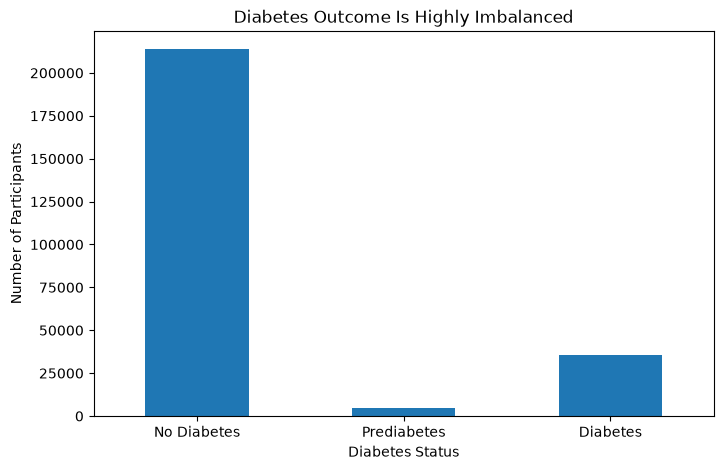

In [ ]:
#  Labels the diabetic categories
diabetes_labels = {
    0: "No Diabetes",
    1: "Prediabetes",
    2: "Diabetes"
}

plot_counts = diabetes_counts.copy()
plot_counts.index = plot_counts.index.map(diabetes_labels)

# Plot the class distribution
plt.figure(figsize=(8, 5))

plot_counts.plot(kind="bar")

plt.title("Diabetes Outcome Is Highly Imbalanced")
plt.xlabel("Diabetes Status")
plt.ylabel("Number of Participants")
plt.xticks(rotation=0)

plt.show()

#### 2.2 Univariate Analysis

In [10]:
# Select important variables for univariate analysis
univariate_columns = [
    "BMI",
    "GenHlth",
    "Age",
    "Income",
    "HighBP",
    "HighChol",
    "PhysActivity"
]

# Display descriptive statistics
df[univariate_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
GenHlth,253680.0,2.511392,1.068477,1.0,2.0,2.0,3.0,5.0
Age,253680.0,8.032119,3.054220,1.0,6.0,8.0,10.0,13.0
Income,253680.0,6.053875,2.071148,1.0,5.0,7.0,8.0,8.0
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0


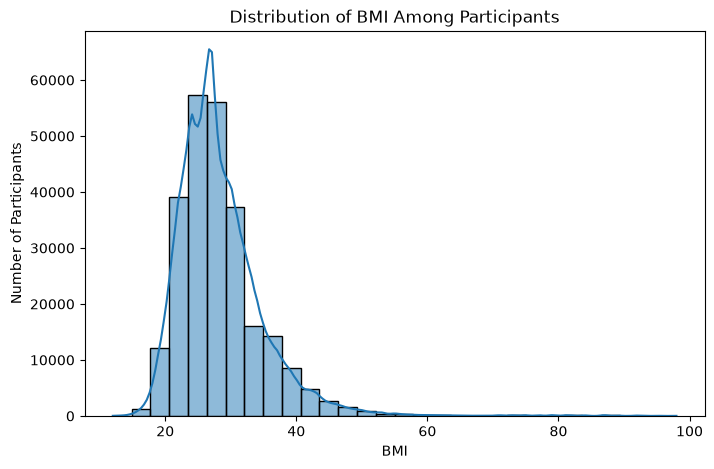

In [11]:
# Examine the distribution of BMI
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="BMI",
    bins=30,
    kde=True
)

plt.title("Distribution of BMI Among Participants")
plt.xlabel("BMI")
plt.ylabel("Number of Participants")

plt.show()

The BMI distribution is centered around the upper 20s. The mean BMI is about 28.4, while the median and mode are both 27. The distribution is somewhat right-skewed because there are some participants with much higher BMI values, reaching as high as 98. I did not automatically remove these values because they may represent real observations, but they are worth keeping in mind during the analysis.

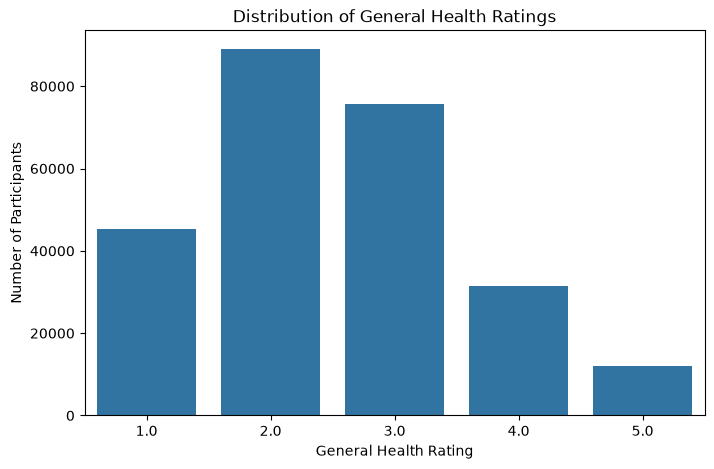

In [12]:
# Look at the distribution of general health ratings
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="GenHlth"
)

plt.title("Distribution of General Health Ratings")
plt.xlabel("General Health Rating")
plt.ylabel("Number of Participants")

plt.show()

In [13]:
# Summary statistics for general health
print("Mean:", df["GenHlth"].mean())
print("Median:", df["GenHlth"].median())
print("Mode:", df["GenHlth"].mode().tolist())

Mean: 2.5113923052664773
Median: 2.0
Mode: [2.0]


Most participants reported relatively good general health. The average general health rating was about 2.5, while both the median and mode were 2. Since the scale runs from better to worse health as the value increases, the distribution suggests that many participants rated their health on the healthier side of the scale.

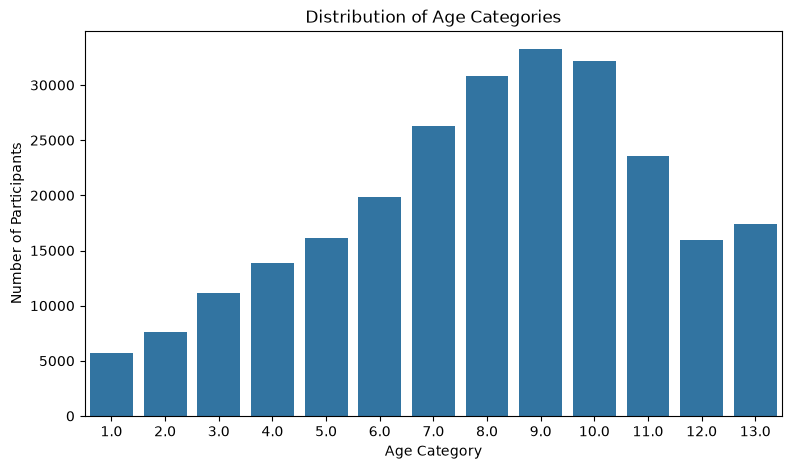

In [14]:
# Look at the distribution of age categories
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Age"
)

plt.title("Distribution of Age Categories")
plt.xlabel("Age Category")
plt.ylabel("Number of Participants")

plt.show()

In [15]:
# Summary statistics for age
print("Mean:", df["Age"].mean())
print("Median:", df["Age"].median())
print("Mode:", df["Age"].mode().tolist())

Mean: 8.032119205298013
Median: 8.0
Mode: [9.0]


The age variable is grouped into categories rather than exact ages. Most participants fall in the middle to older age categories, with the average category around 8 and the most common category being 9. This suggests that the dataset includes a relatively large number of middle-aged and older adults.

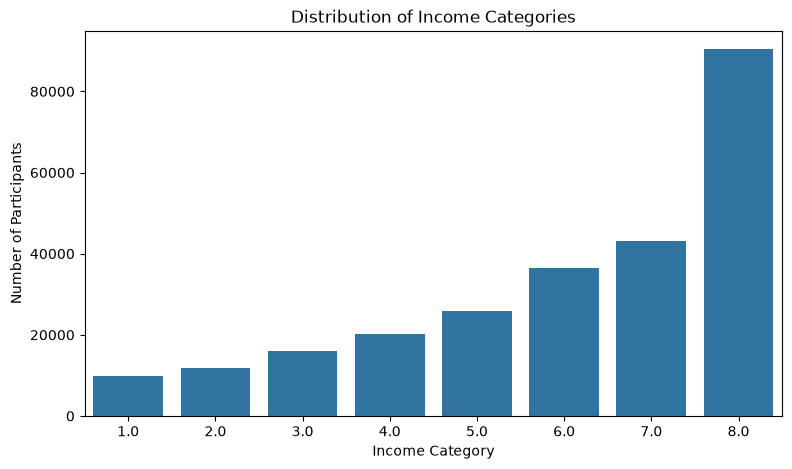

In [16]:
# Look at the distribution of income categories
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Income"
)

plt.title("Distribution of Income Categories")
plt.xlabel("Income Category")
plt.ylabel("Number of Participants")

plt.show()

In [17]:
# Summary statistics for income
print("Mean:", df["Income"].mean())
print("Median:", df["Income"].median())
print("Mode:", df["Income"].mode().tolist())

Mean: 6.053874960580258
Median: 7.0
Mode: [8.0]


The income distribution is concentrated toward the higher categories. The median income category is 7 and the most common category is 8. This suggests that many participants in the dataset reported income levels toward the upper end of the available scale.

In [18]:
# Count the values for selected binary health variables
binary_columns = ["HighBP", "HighChol", "PhysActivity"]

for column in binary_columns:
    print(f"\n{column}")
    print(df[column].value_counts().sort_index())


HighBP
HighBP
0.0    144851
1.0    108829
Name: count, dtype: int64

HighChol
HighChol
0.0    146089
1.0    107591
Name: count, dtype: int64

PhysActivity
PhysActivity
0.0     61760
1.0    191920
Name: count, dtype: int64


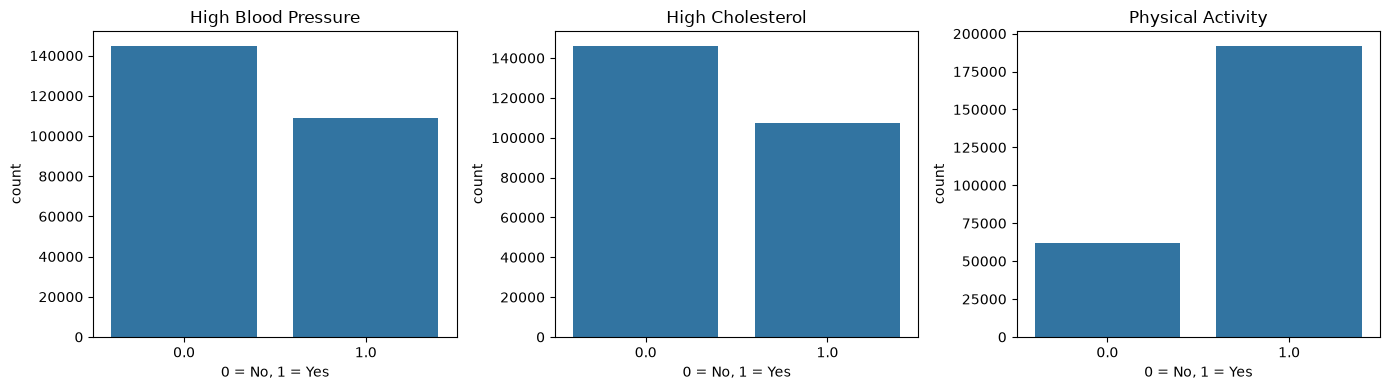

In [19]:
# Plot binary health variables
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

sns.countplot(data=df, x="HighBP", ax=axes[0])
axes[0].set_title("High Blood Pressure")
axes[0].set_xlabel("0 = No, 1 = Yes")

sns.countplot(data=df, x="HighChol", ax=axes[1])
axes[1].set_title("High Cholesterol")
axes[1].set_xlabel("0 = No, 1 = Yes")

sns.countplot(data=df, x="PhysActivity", ax=axes[2])
axes[2].set_title("Physical Activity")
axes[2].set_xlabel("0 = No, 1 = Yes")

plt.tight_layout()
plt.show()

The binary variables show that many participants reported physical activity, while smaller proportions reported high blood pressure or high cholesterol.

#### 2.3 Bivariate Analysis

### 3. Conclusions

#### 3.1 Expected and Unexpected Findings

#### 3.2 Disqualified Data

#### 3.3 Suggested Supervised and Unsupervised Analyses